# MeterTrace — Notebook 03: Feature Engineering

**Project:** MeterTrace: Electricity Theft Detection and Consumption Anomaly Analysis
**Phase:** 3 of 8

## Purpose
The classical models in Notebook 04 (Logistic Regression, Random Forest, Isolation Forest) cannot read a
1,000-day time series directly. They need a short list of **numbers that describe each customer**: these
are the *engineered features*. This notebook turns every customer's daily history into 11 easy-to-explain
features.

## Data rules followed in this notebook
1. We use the **exact train / validation / test split** saved in Notebook 02 (`customers.csv`).
2. **Nothing is fitted** in this notebook. Every feature uses only **one customer's own readings**, so no
   information can flow between customers or between splits. (Scaling for Logistic Regression will be
   fitted on training customers in Notebook 04.)
3. `FLAG` (the label) and `CONS_NO` (the customer ID) are **never** used to compute a feature. The label is
   stored next to the features only so that Notebook 04 can train and evaluate.
4. The 3 Oct 2014 artefact cannot leak: Notebook 02 already blanked that day for everyone, and here we
   leave that day (and the inserted 18 Sep 2016) out of all calculations.
5. All features come from the **observed daily readings** in `daily_clean.parquet` (capped, **not
   imputed**). The imputed weekly values are never used, so copied or interpolated weeks cannot create
   artificial zeros, spikes, drops or volatility.

## The 11 features
| # | Feature | How it is calculated (per customer, observed days only) |
|---|---|---|
| 1 | `mean_kwh` | Average daily reading |
| 2 | `median_kwh` | Median daily reading (robust to a few extreme days) |
| 3 | `std_kwh` | Standard deviation of daily readings (spread) |
| 4 | `max_kwh` | Largest daily reading (after the Notebook 02 cap) |
| 5 | `zero_ratio` | Days reading exactly 0 ÷ observed days |
| 6 | `missing_ratio` | Days without a reading ÷ 1,033 possible days |
| 7 | `volatility` | Average absolute change between two **consecutive observed** days ÷ the customer's average |
| 8 | `longest_zero_run_days` | Longest run of consecutive observed days reading 0 |
| 9 | `spike_frequency` | Share of comparable days that are ≥ 3 × the average of the previous 7 days |
| 10 | `drop_frequency` | Share of comparable days that are ≤ ⅓ × the average of the previous 7 days |
| 11 | `consumption_change` | (later-half average − earlier-half average) ÷ (later + earlier), from −1 to +1 |

Exact definitions, including edge cases, are given next to each calculation below.

## Outputs
- `data/processed/features_train.parquet`, `features_validation.parquet`, `features_test.parquet`
  (one row per customer: 11 features + `FLAG`, same row order as the `weekly_*.npz` files)
- `data/processed/features_metadata.json` (feature list and the constants used)
- `outputs/results/03_feature_definitions.csv`, `outputs/results/03_feature_summary_train.csv` (committed)

## 0. Setup

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

In [2]:
# ---- Paths (work from the notebooks/ folder or from the project root) ----
if Path.cwd().name == "notebooks":
    PROJECT_ROOT = Path.cwd().parent
else:
    PROJECT_ROOT = Path.cwd()

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ---- Parameters saved by Notebook 02 (never recomputed here) ----
preprocessing_params = json.loads((PROCESSED_DIR / "preprocessing_params.json").read_text())
RANDOM_STATE = preprocessing_params["random_state"]
GLITCH_DATE = preprocessing_params["blanked_glitch_date"]        # "2014-10-03"
ABSENT_DATE = preprocessing_params["inserted_absent_date"]       # "2016-09-18"
N_POSSIBLE_DAYS = preprocessing_params["n_possible_days_for_missing_ratio"]

# ---- Feature constants (fixed by reasoning, never tuned on results) ----
BASELINE_DAYS = 7          # spikes/drops are compared with the previous 7 days
MIN_BASELINE_DAYS = 4      # ...which must contain at least 4 observed days
MIN_BASELINE_KWH = 1.0     # ...and an average of at least 1 kWh/day (below that, changes are mostly noise)
SPIKE_MULTIPLIER = 3.0     # spike: reading >= 3 x recent average
DROP_FRACTION = 1 / 3      # drop:  reading <= 1/3 x recent average

LABEL_COLUMN = "FLAG"
SPLITS = ["train", "validation", "test"]

NORMAL_COLOR = "#2a78d6"
THEFT_COLOR = "#eb6834"
NEUTRAL_COLOR = "#52514e"
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
pd.set_option("display.max_columns", 14)

print("Loaded preprocessing parameters from Notebook 02:")
print("  blanked day:", GLITCH_DATE, "| inserted day:", ABSENT_DATE, "| possible days:", N_POSSIBLE_DAYS)

Loaded preprocessing parameters from Notebook 02:
  blanked day: 2014-10-03 | inserted day: 2016-09-18 | possible days: 1033


## 1. Load the customer table and the cleaned daily readings
`customers.csv` holds the split for every customer. `daily_clean.parquet` holds the daily readings after
Notebook 02: dates sorted, 18 Sep 2016 inserted, 3 Oct 2014 blanked, extreme values capped, and **missing
days still missing** (`NaN`).

In [3]:
customers = pd.read_csv(PROCESSED_DIR / "customers.csv", index_col="CONS_NO")
daily = pd.read_parquet(PROCESSED_DIR / "daily_clean.parquet")

print("customers.csv:", customers.shape)
print("daily_clean.parquet:", daily.shape)
print(customers["split"].value_counts().to_string())

customers.csv: (42372, 10)
daily_clean.parquet: (42372, 1035)
split
train                     29657
test                       6356
validation                 6354
excluded (no readings)        5


### Keep only modelling customers and drop the two artificial days
- The 5 customers with no readings have `split = "excluded (no readings)"` and get no features.
- **3 Oct 2014** and **18 Sep 2016** are missing for *everybody* by construction (Notebook 02). They say
  nothing about any individual customer, so we remove these two columns before computing anything. This
  also guarantees that the 3 Oct 2014 artefact cannot influence any feature. The days on either side of
  them simply become neighbours.

In [4]:
modelling_ids = customers.index[customers["split"].isin(SPLITS)]

daily = daily.loc[modelling_ids].drop(columns=[GLITCH_DATE, ABSENT_DATE]).copy()   # .copy() makes one compact table
daily.columns = pd.to_datetime(daily.columns)

print("Daily readings used for features:", daily.shape)
print("Number of days equals the 'possible days' from Notebook 02:", daily.shape[1] == N_POSSIBLE_DAYS)
print("3 Oct 2014 still present?", pd.Timestamp(GLITCH_DATE) in daily.columns)

Daily readings used for features: (42367, 1033)
Number of days equals the 'possible days' from Notebook 02: True
3 Oct 2014 still present? False


In [5]:
# Masks and counts reused by several features
is_observed = daily.notna()
observed_days = is_observed.sum(axis=1)

print("Fewest observed days for any modelling customer:", int(observed_days.min()))
print("Customers with fewer than 10 observed days:", int((observed_days < 10).sum()))

Fewest observed days for any modelling customer: 3
Customers with fewer than 10 observed days: 3


## 2. Level and spread features (1–4)
Pandas skips missing values by default, so these use **only observed days**.

- `std_kwh` uses `ddof=0` (the population standard deviation), so a customer with very few readings
  still gets a defined value instead of `NaN`.
- `max_kwh` can be at most the Notebook 02 cap.

In [6]:
features = pd.DataFrame(index=daily.index)
features["mean_kwh"] = daily.mean(axis=1)
features["median_kwh"] = daily.median(axis=1)
features["std_kwh"] = daily.std(axis=1, ddof=0)
features["max_kwh"] = daily.max(axis=1)

print("Cap from Notebook 02:", preprocessing_params["cap_value_kwh_per_day"], "| largest max_kwh:", features["max_kwh"].max())
features.describe().round(2)

Cap from Notebook 02: 2112.0 | largest max_kwh: 2112.0


,mean_kwh,median_kwh,std_kwh,max_kwh
count,42367.00,42367.00,42367.00,42367.00
mean,9.34,8.21,5.88,50.91
std,34.14,35.71,17.74,193.29
min,0.00,0.00,0.00,0.00
25%,1.98,1.00,1.48,11.17
50%,5.69,4.78,3.28,23.01
75%,10.23,9.04,5.77,37.65
max,2112.00,2112.00,888.55,2112.00


## 3. Zero-reading and missing-reading ratios (features 5–6)
- `zero_ratio` = observed days with a reading of exactly 0 ÷ observed days. A missing day is **not** a
  zero day (`NaN == 0` is `False`).
- `missing_ratio` = days without a reading ÷ 1,033 possible days. This must equal the value Notebook 02
  saved in `customers.csv` *before* any imputation; we recompute it and check.

In [7]:
is_zero = daily == 0
features["zero_ratio"] = is_zero.sum(axis=1) / observed_days
features["missing_ratio"] = 1 - observed_days / N_POSSIBLE_DAYS

matches_notebook_02 = np.allclose(features["missing_ratio"], customers.loc[features.index, "missing_ratio"], atol=1e-6)
print("missing_ratio matches the value saved by Notebook 02:", matches_notebook_02)
features[["zero_ratio", "missing_ratio"]].describe().round(3)

missing_ratio matches the value saved by Notebook 02: True


,zero_ratio,missing_ratio
count,42367.000,42367.000
mean,0.180,0.256
std,0.320,0.288
min,0.000,0.000
25%,0.000,0.012
50%,0.007,0.105
75%,0.169,0.618
max,1.000,0.997


## 4. Volatility (feature 7)
How much does consumption jump around from one day to the next?

1. `daily.diff(axis=1)` gives *today − yesterday* for every day. If either day is missing, the result is
   `NaN`, so only **pairs of consecutive observed days** are used. No imputed value is involved.
2. We average the **absolute** changes and divide by the customer's average consumption, so a large and a
   small consumer can be compared. For example, `volatility = 0.4` means "on a typical day, consumption
   changes by 40% of this customer's average".
3. Edge cases: if the customer's average is 0 (they only ever read 0), nothing changes, so
   `volatility = 0`. The same applies if the customer has no pair of consecutive observed days.

In [8]:
absolute_daily_change = daily.diff(axis=1).abs()
mean_absolute_change = absolute_daily_change.mean(axis=1)          # NaN if no consecutive observed pair
consecutive_pairs = absolute_daily_change.notna().sum(axis=1)

volatility = mean_absolute_change / features["mean_kwh"]
features["volatility"] = volatility.where((features["mean_kwh"] > 0) & (consecutive_pairs > 0), 0.0)

print("Customers with no consecutive observed pair:", int((consecutive_pairs == 0).sum()))
print("Customers whose average is 0 (volatility set to 0):", int((features["mean_kwh"] == 0).sum()))
features["volatility"].describe().round(3)

Customers with no consecutive observed pair: 0
Customers whose average is 0 (volatility set to 0): 2109


count    42367.000
mean         0.312
std          0.307
min          0.000
25%          0.183
50%          0.238
75%          0.322
max          2.072
Name: volatility, dtype: float64

## 5. Longest run of zero readings (feature 8)
The longest stretch of **consecutive observed days reading 0**. A missing day ends the run, because we do
not know what the meter would have read. We use the same NumPy trick as in Notebook 01 (no loop over
customers):

1. For each day, write the day's position if the reading is **not** zero, otherwise `-1`.
2. `np.maximum.accumulate` carries forward "the position of the most recent non-zero day".
3. Today's position minus that value is the length of the zero run ending today.
4. The maximum per customer is the longest zero run.

In [9]:
zero_array = is_zero.to_numpy()
day_position = np.arange(zero_array.shape[1])

last_non_zero_position = np.where(zero_array, -1, day_position)
last_non_zero_position = np.maximum.accumulate(last_non_zero_position, axis=1)
current_zero_run = day_position - last_non_zero_position

features["longest_zero_run_days"] = current_zero_run.max(axis=1)
features["longest_zero_run_days"].describe().round(1)

count    42367.0
mean        60.4
std        140.2
min          0.0
25%          0.0
50%          2.0
75%         40.0
max       1033.0
Name: longest_zero_run_days, dtype: float64

## 6. Spikes and sudden drops (features 9–10)
A day is compared with the same customer's **recent average**: the mean of the **previous 7 days**
(observed days only; at least 4 of the 7 must be observed). Today is *not* part of its own baseline
(`shift(1)`).

- **Spike day:** reading ≥ 3 × recent average
- **Drop day:** reading ≤ ⅓ × recent average

A day is only **comparable** if it is observed **and** the recent average is at least 1 kWh/day. Below
that, a change from 0.1 to 0.4 kWh would count as a "spike" even though it is just noise. Then:

- `spike_frequency` = spike days ÷ comparable days
- `drop_frequency` = drop days ÷ comparable days

If a customer has **no** comparable day (for example an all-zero meter), both frequencies are set to 0,
because no spike or drop can be detected.

*How the code works:* pandas `rolling` works down rows, but our days run across columns. So we transpose
(`.T`), compute the rolling mean, shift by one day, and transpose back.

In [10]:
recent_average = daily.T.rolling(BASELINE_DAYS, min_periods=MIN_BASELINE_DAYS).mean().shift(1).T

is_comparable = is_observed & (recent_average >= MIN_BASELINE_KWH)
ratio_to_recent = daily / recent_average

is_spike_day = is_comparable & (ratio_to_recent >= SPIKE_MULTIPLIER)
is_drop_day = is_comparable & (ratio_to_recent <= DROP_FRACTION)

comparable_days = is_comparable.sum(axis=1)
features["spike_frequency"] = (is_spike_day.sum(axis=1) / comparable_days).where(comparable_days > 0, 0.0)
features["drop_frequency"] = (is_drop_day.sum(axis=1) / comparable_days).where(comparable_days > 0, 0.0)

print("Customers with no comparable day (frequencies set to 0):", int((comparable_days == 0).sum()))
features[["spike_frequency", "drop_frequency"]].describe().round(4)

Customers with no comparable day (frequencies set to 0): 4076


,spike_frequency,drop_frequency
count,42367.0000,42367.0000
mean,0.0090,0.0571
std,0.0198,0.1293
min,0.0000,0.0000
25%,0.0000,0.0020
50%,0.0020,0.0133
75%,0.0088,0.0451
max,1.0000,1.0000


## 7. Change between earlier and later periods (feature 11)
Many meters started reporting at different times (Notebook 01), so fixed calendar periods would leave many
customers without an "early" value. Instead, each customer's **own observed days** are split in half in
time order:

- **earlier half** = the first half of the customer's observed days,
- **later half** = the second half.

$$\text{consumption\_change} = \frac{\text{later average} - \text{earlier average}}{\text{later average} + \text{earlier average}}$$

This always lies between **−1** (consumption fell to zero) and **+1** (consumption started from zero);
0 means no change. If both averages are 0, the change is 0. Every modelling customer has at least 2
observed days, so both halves always contain at least one day.

In [11]:
observed_rank = is_observed.cumsum(axis=1)                         # 1 for the first observed day, 2 for the second...
half_point = observed_days / 2

is_earlier_half = is_observed & observed_rank.le(half_point, axis=0)
is_later_half = is_observed & observed_rank.gt(half_point, axis=0)

earlier_average = daily.where(is_earlier_half).mean(axis=1)
later_average = daily.where(is_later_half).mean(axis=1)
average_sum = later_average + earlier_average

features["consumption_change"] = ((later_average - earlier_average) / average_sum).where(average_sum > 0, 0.0)

print("Customers with an empty earlier or later half:",
      int((is_earlier_half.sum(axis=1) == 0).sum() + (is_later_half.sum(axis=1) == 0).sum()))
features["consumption_change"].describe().round(3)

Customers with an empty earlier or later half: 0


count    42367.000
mean         0.031
std          0.363
min         -1.000
25%         -0.083
50%          0.030
75%          0.168
max          1.000
Name: consumption_change, dtype: float64

## 8. Quality checks: missing and infinite values
Every feature must be a real, finite number for every modelling customer. Otherwise the models in
Notebook 04 would fail or silently drop customers.

In [12]:
FEATURE_COLUMNS = list(features.columns)

quality = pd.DataFrame({
    "NaN values": features.isna().sum(),
    "Infinite values": np.isinf(features.to_numpy()).sum(axis=0),
    "Min": features.min(),
    "Max": features.max(),
})
print("Number of features:", len(FEATURE_COLUMNS))
print("Customers:", len(features))
print("Total NaN:", int(quality["NaN values"].sum()), "| Total infinite:", int(quality["Infinite values"].sum()))
quality.round(4)

Number of features: 11
Customers: 42367
Total NaN: 0 | Total infinite: 0


,NaN values,Infinite values,Min,Max
mean_kwh,0,0,0.0,2112.0000
median_kwh,0,0,0.0,2112.0000
std_kwh,0,0,0.0,888.5469
max_kwh,0,0,0.0,2112.0000
zero_ratio,0,0,0.0,1.0000
missing_ratio,0,0,0.0,0.9971
volatility,0,0,0.0,2.0716
longest_zero_run_days,0,0,0.0,1033.0000
spike_frequency,0,0,0.0,1.0000
drop_frequency,0,0,0.0,1.0000


**Result:**
- **Complete:** all 11 features are finite for all 42,367 modelling customers, with 0 `NaN` and 0
  infinite values. The edge-case rules above are what make this possible.
- **Edge cases that needed a rule:**
  - **All-zero meters:** 2,109 customers have an average of 0, so their `volatility` is 0.
  - **No comparable day:** 4,076 customers never have a recent average of at least 1 kWh, so their
    spike and drop frequencies are 0. Most are all-zero or very-low-consumption meters.
  - **Few readings:** the fewest observed days for any customer is 3, so every customer has at least one
    day in each half for `consumption_change`.
- **Ranges are sensible:**
  - Ratios and frequencies lie between 0 and 1, and `consumption_change` between −1 and +1.
  - `max_kwh` never exceeds the Notebook 02 cap of 2,112 kWh.
  - The largest `longest_zero_run_days` (1,033) belongs to meters that read 0 on every possible day.

## 9. A first look at the features (training customers only)
To understand the features, we compare their **medians** for theft and normal customers, and compute
each feature's **ROC-AUC on its own** (1.0 = perfect ranking, 0.5 = random, below 0.5 = *lower* values
are linked to theft).

We use **training customers only**: validation and test customers stay untouched until later notebooks.
This is exploration, not model training, so nothing is fitted or selected here.

In [13]:
train_ids = customers.index[customers["split"] == "train"]
train_features = features.loc[train_ids]
train_labels = customers.loc[train_ids, LABEL_COLUMN]

single_feature_auc = []
for feature_name in FEATURE_COLUMNS:
    single_feature_auc.append(roc_auc_score(train_labels, train_features[feature_name]))

feature_summary_train = pd.DataFrame({
    "Median, normal (train)": train_features[train_labels == 0].median(),
    "Median, theft (train)": train_features[train_labels == 1].median(),
    "ROC-AUC on its own (train)": single_feature_auc,
}).round(4)
feature_summary_train

,"Median, normal (train)","Median, theft (train)",ROC-AUC on its own (train)
mean_kwh,5.4353,8.6887,0.6530
median_kwh,4.5800,6.7550,0.6174
std_kwh,3.0970,6.0028,0.7070
max_kwh,21.9000,37.9400,0.6974
zero_ratio,0.0074,0.0042,0.4654
missing_ratio,0.0949,0.2115,0.5679
volatility,0.2396,0.2264,0.4647
longest_zero_run_days,2.0000,2.0000,0.4649
spike_frequency,0.0020,0.0038,0.5770
drop_frequency,0.0131,0.0155,0.5379


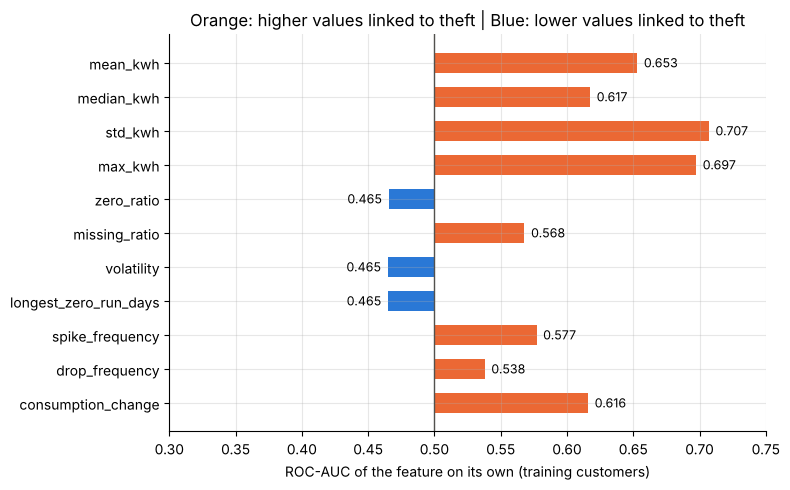

In [14]:
auc_values = feature_summary_train["ROC-AUC on its own (train)"]
bar_colors = np.where(auc_values >= 0.5, THEFT_COLOR, NORMAL_COLOR)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(FEATURE_COLUMNS, auc_values - 0.5, left=0.5, color=bar_colors, height=0.6)
ax.axvline(0.5, color=NEUTRAL_COLOR, linewidth=1)
for row, value in enumerate(auc_values):
    ax.text(value + (0.005 if value >= 0.5 else -0.005), row, f"{value:.3f}", va="center",
            ha="left" if value >= 0.5 else "right", fontsize=9)
ax.set_xlim(0.3, 0.75)
ax.invert_yaxis()
ax.set_xlabel("ROC-AUC of the feature on its own (training customers)")
ax.set_title("Orange: higher values linked to theft | Blue: lower values linked to theft")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_single_feature_auc_train.png", dpi=120)
plt.show()

### How similar are the features to each other? (training customers)
Strongly correlated features carry overlapping information. This matters for **Logistic Regression**,
whose coefficients become hard to interpret when inputs are highly correlated. Random Forest is less
affected.

In [15]:
train_correlation = train_features.corr(method="spearman").round(2)
train_correlation

,mean_kwh,median_kwh,std_kwh,max_kwh,zero_ratio,missing_ratio,volatility,longest_zero_run_days,spike_frequency,drop_frequency,consumption_change
mean_kwh,1.00,0.96,0.83,0.82,-0.57,0.00,-0.31,-0.54,0.00,-0.09,0.14
median_kwh,0.96,1.00,0.71,0.71,-0.60,0.00,-0.37,-0.58,-0.10,-0.18,0.12
std_kwh,0.83,0.71,1.00,0.95,-0.32,-0.03,-0.05,-0.30,0.33,0.24,0.16
max_kwh,0.82,0.71,0.95,1.00,-0.35,-0.07,-0.03,-0.32,0.32,0.21,0.13
zero_ratio,-0.57,-0.60,-0.32,-0.35,1.00,-0.12,0.22,0.98,0.16,0.27,-0.05
missing_ratio,0.00,0.00,-0.03,-0.07,-0.12,1.00,-0.03,-0.17,-0.08,-0.11,0.01
volatility,-0.31,-0.37,-0.05,-0.03,0.22,-0.03,1.00,0.19,0.47,0.57,-0.03
longest_zero_run_days,-0.54,-0.58,-0.30,-0.32,0.98,-0.17,0.19,1.00,0.16,0.26,-0.05
spike_frequency,0.00,-0.10,0.33,0.32,0.16,-0.08,0.47,0.16,1.00,0.74,0.07
drop_frequency,-0.09,-0.18,0.24,0.21,0.27,-0.11,0.57,0.26,0.74,1.00,-0.01


**What we see (training customers only).**
- **Strongest on their own:** the consumption-level and spread features: `std_kwh` (ROC-AUC 0.707),
  `max_kwh` (0.697) and `mean_kwh` (0.653). Theft-labelled customers have *higher* and more variable
  consumption, which matches Notebook 01.
- **Also useful:**
  - `consumption_change` (0.616): the median theft customer's later half is higher than their earlier
    half (0.136 vs 0.023 for normal customers).
  - `spike_frequency` (0.577) and `missing_ratio` (0.568).
- **Weak, and lower values point towards theft:** `zero_ratio`, `volatility` and `longest_zero_run_days`
  (each about 0.465). Zero readings are slightly *more* common among normal customers, again matching
  Notebook 01.
- **Overlapping features** (Spearman correlation):
  - `zero_ratio` and `longest_zero_run_days`: 0.98, almost the same information.
  - `mean_kwh` and `median_kwh`: 0.96.
  - `std_kwh` and `max_kwh`: 0.95.
  - `spike_frequency` and `drop_frequency`: 0.74.

  We keep all 11 because each is easy to explain and the team asked for them. When interpreting Logistic
  Regression coefficients in Notebook 04, remember that correlated features share credit.

These numbers describe single features, not models. No feature was selected or tuned based on them.

## 10. Save the feature datasets
One file per split. Rows are put in **exactly the same order as the `weekly_*.npz` files** from
Notebook 02, so row *i* in every file is the same customer. This makes it easy to compare models later.

`FLAG` is saved as the **last column** so Notebook 04 can train and evaluate. It is a label, **not** a
feature: Notebook 04 must select its inputs with the `feature_columns` list from `features_metadata.json`.

In [16]:
for split_name in SPLITS:
    weekly_file = np.load(PROCESSED_DIR / f"weekly_{split_name}.npz")
    row_order = weekly_file["customer_ids"]

    split_table = features.loc[row_order].copy()
    split_table[LABEL_COLUMN] = customers.loc[row_order, LABEL_COLUMN].to_numpy()
    split_table.index.name = "CONS_NO"
    split_table.to_parquet(PROCESSED_DIR / f"features_{split_name}.parquet")
    print(f"features_{split_name}.parquet: {split_table.shape[0]:,} customers x {split_table.shape[1]} columns "
          f"({len(FEATURE_COLUMNS)} features + {LABEL_COLUMN})")

features_train.parquet: 29,657 customers x 12 columns (11 features + FLAG)
features_validation.parquet: 6,354 customers x 12 columns (11 features + FLAG)
features_test.parquet: 6,356 customers x 12 columns (11 features + FLAG)


In [17]:
feature_definitions = pd.DataFrame({
    "feature": FEATURE_COLUMNS,
    "definition": [
        "Average daily reading (observed days)",
        "Median daily reading (observed days)",
        "Standard deviation of daily readings, ddof=0 (observed days)",
        "Largest daily reading (after the Notebook 02 cap)",
        "Days reading exactly 0 / observed days",
        "Days without a reading / 1,033 possible days (equals Notebook 02 missing_ratio)",
        "Mean |today - yesterday| over consecutive observed days / mean_kwh (0 if mean_kwh = 0)",
        "Longest run of consecutive observed days reading 0 (a missing day ends the run)",
        "Comparable days with reading >= 3 x mean of previous 7 days / comparable days (0 if none)",
        "Comparable days with reading <= 1/3 x mean of previous 7 days / comparable days (0 if none)",
        "(later-half mean - earlier-half mean) / (sum of both) over the customer's observed days (0 if both 0)",
    ],
})

features_metadata = {
    "feature_columns": FEATURE_COLUMNS,
    "label_column": LABEL_COLUMN,
    "not_features": ["CONS_NO (index)", LABEL_COLUMN],
    "source": "daily_clean.parquet (capped, not imputed); 2014-10-03 and 2016-09-18 removed before calculation",
    "row_order": "same as weekly_<split>.npz customer_ids",
    "constants": {
        "baseline_days": BASELINE_DAYS,
        "min_baseline_days": MIN_BASELINE_DAYS,
        "min_baseline_kwh": MIN_BASELINE_KWH,
        "spike_multiplier": SPIKE_MULTIPLIER,
        "drop_fraction": round(DROP_FRACTION, 6),
    },
    "fitted_parameters": "none (every feature uses only the customer's own readings)",
}
(PROCESSED_DIR / "features_metadata.json").write_text(json.dumps(features_metadata, indent=2))
feature_definitions.to_csv(RESULTS_DIR / "03_feature_definitions.csv", index=False)
feature_summary_train.to_csv(RESULTS_DIR / "03_feature_summary_train.csv")
feature_definitions

,feature,definition
0,mean_kwh,Average daily reading (observed days)
1,median_kwh,Median daily reading (observed days)
2,std_kwh,"Standard deviation of daily readings, ddof=0 (..."
3,max_kwh,Largest daily reading (after the Notebook 02 cap)
4,zero_ratio,Days reading exactly 0 / observed days
5,missing_ratio,"Days without a reading / 1,033 possible days (..."
6,volatility,Mean |today - yesterday| over consecutive obse...
7,longest_zero_run_days,Longest run of consecutive observed days readi...
8,spike_frequency,Comparable days with reading >= 3 x mean of pr...
9,drop_frequency,Comparable days with reading <= 1/3 x mean of ...


## 11. Verify the saved files
We reload every file and check that:
- each file contains **exactly** the customers of its split in `customers.csv`,
- the row order matches the `weekly_*.npz` file,
- no customer appears in two splits,
- the labels match `customers.csv`,
- the columns are exactly the 11 features plus `FLAG`, and
- there are no `NaN` or infinite values.

Every line must print `True`.

In [18]:
saved_ids = {}
for split_name in SPLITS:
    saved = pd.read_parquet(PROCESSED_DIR / f"features_{split_name}.parquet")
    weekly_ids = np.load(PROCESSED_DIR / f"weekly_{split_name}.npz")["customer_ids"]
    expected_ids = set(customers.index[customers["split"] == split_name])
    saved_ids[split_name] = set(saved.index)

    print(f"--- {split_name} ({len(saved):,} rows) ---")
    print("  same customers as customers.csv:  ", set(saved.index) == expected_ids)
    print("  same row order as weekly npz:     ", bool((saved.index.to_numpy() == weekly_ids).all()))
    print("  labels match customers.csv:       ",
          bool((saved[LABEL_COLUMN].to_numpy() == customers.loc[saved.index, LABEL_COLUMN].to_numpy()).all()))
    print("  columns = 11 features + FLAG:     ", list(saved.columns) == FEATURE_COLUMNS + [LABEL_COLUMN])
    print("  no NaN or infinite feature values:", bool(np.isfinite(saved[FEATURE_COLUMNS].to_numpy()).all()))

print("--- across splits ---")
print("  no customer in two splits:", len(saved_ids["train"] & saved_ids["validation"]) == 0
      and len(saved_ids["train"] & saved_ids["test"]) == 0 and len(saved_ids["validation"] & saved_ids["test"]) == 0)

--- train (29,657 rows) ---
  same customers as customers.csv:   True
  same row order as weekly npz:      True
  labels match customers.csv:        True
  columns = 11 features + FLAG:      True
  no NaN or infinite feature values: True
--- validation (6,354 rows) ---
  same customers as customers.csv:   True
  same row order as weekly npz:      True
  labels match customers.csv:        True
  columns = 11 features + FLAG:      True
  no NaN or infinite feature values: True
--- test (6,356 rows) ---


  same customers as customers.csv:   True
  same row order as weekly npz:      True
  labels match customers.csv:        True
  columns = 11 features + FLAG:      True
  no NaN or infinite feature values: True
--- across splits ---
  no customer in two splits: True


## 12. Summary

In [19]:
shape_summary = pd.DataFrame({
    "Rows (customers)": [len(saved_ids[split_name]) for split_name in SPLITS],
    "Feature columns": [len(FEATURE_COLUMNS)] * len(SPLITS),
    "Theft": [int(customers.loc[list(saved_ids[split_name]), LABEL_COLUMN].sum()) for split_name in SPLITS],
}, index=SPLITS)
shape_summary

,Rows (customers),Feature columns,Theft
train,29657,11,2530
validation,6354,11,540
test,6356,11,542


## What We Learned
Key ideas to be able to explain in the viva:

1. **Why engineer features?** Classical models need a fixed-length list of numbers per customer. Eleven
   well-chosen summaries turn a 1,033-day history into something Logistic Regression, Random Forest and
   Isolation Forest can use. The LSTM and autoencoder instead learn directly from the weekly sequence.
2. **Row-wise features are leakage-free.** Every feature uses only one customer's own readings, so
   nothing had to be fitted, and validation or test customers cannot influence training. Anything that
   *is* fitted, such as the Logistic Regression scaler, will be fitted on training customers in
   Notebook 04.
3. **Compute from real observations, not imputed values.** All features use observed daily readings.
   Filled-in weeks could otherwise create fake zeros, spikes, drops or volatility. Missing days are
   excluded from averages and end zero runs.
4. **Handle edge cases explicitly.** All-zero meters, very-low consumers and customers with few readings
   need a rule (for example "no comparable day → frequency 0"). Writing these rules down is what keeps the
   feature tables free of `NaN` and infinite values.
5. **Remove artefacts before computing features.** The 3 Oct 2014 day, whose only readings came from theft
   customers, and the inserted 18 Sep 2016 were removed before any calculation. No feature can learn "who
   reported on 3 Oct 2014".
6. **Relative features make customers comparable.** Volatility is divided by the customer's own average,
   spikes and drops are measured against the customer's own recent week, and `consumption_change` is
   bounded between −1 and +1. Large and small consumers can therefore be compared fairly.
7. **Look at features, but don't select them on the test set.** On training customers, level and spread
   features are the strongest single signals, and several features overlap strongly. We noted this
   without dropping or tuning anything.
8. **Keep files aligned.** Every feature file has the same customers and the same row order as the weekly
   sequence files, and labels are stored separately from the feature list, so later notebooks cannot mix
   them up.